# Phase 4b — Coherence Rigor

Revision step 10 from `NEXT_STEPS.md` (PeerJ resubmission). Reviewers asked whether a "paradox" track
is a real audio–lyrics disagreement or just a probe error. This notebook:

1. reports **probe accuracy** (R², MAE per dimension) on the shared held-out test split from Phase 5b;
2. recomputes coherence for all 2,075 multimodal tracks with **cross-fitted** probes, so no track is scored
   by a probe that saw it in training (Phase 4 scored its own training tracks);
3. adds **bootstrap uncertainty**: 200 bootstrap probes per fold give every track a 95% interval, and a track
   counts as a *robust paradox* only when the whole interval sits on the paradox side;
4. compares **cosine** coherence (Phase 4) with a **Euclidean** alternative;
5. runs proper tests for the **quadrant** and **genre** claims in the draft;
6. checks whether coherence relates to retrieval quality (does it carry information?).

`genres` is read only in section 7 (evaluation). The lyrics AV annotations are read only in section 0 to check the dataset's ground truth.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kruskal, mannwhitneyu
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import r2_score, mean_absolute_error

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
SEED    = 42
N_BOOT  = 200
N_FOLDS = 5
RIDGE_ALPHAS = np.logspace(-2, 5, 15)          # Phase 4 grid stopped at 1000 and chose 1000 (its upper edge)
CENTER  = np.array([0.5, 0.5])
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
QCOL    = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}

audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))

sids = lyrics_df['song_id'].tolist()                                    # 2,075 multimodal tracks
arow = {s: i for i, s in enumerate(audio_df['song_id'])}
X_a  = np.vstack(audio_df['audio_clap'].values)[[arow[s] for s in sids]].astype(np.float64)
X_l  = np.vstack(lyrics_df['lyrics_sbert'].values).astype(np.float64)
lab  = merged.set_index('song_id').loc[sids]
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
quad = lab['quadrant'].values
print(f'{len(sids)} tracks  CLAP {X_a.shape}  SBERT {X_l.shape}')

2075 tracks  CLAP (2075, 512)  SBERT (2075, 768)


## 0. Ground truth check: does MERGE label any audio–lyrics paradoxes?
MERGE ships separate AV annotations for the lyrics dataset. If audio and lyric annotations disagreed for some
tracks, those would be labelled paradoxes we could validate against.

In [2]:
stem = lab['lyrics_path'].map(lambda p: os.path.splitext(os.path.basename(p))[0])
lav  = pd.read_csv(os.path.join(ROOT, 'MERGE_Lyrics_Balanced', 'merge_lyrics_balanced_av_values.csv')).set_index('Song')
Y_lyr = np.c_[stem.map(lav['Arousal']).values, stem.map(lav['Valence']).values]
gap = np.linalg.norm(Y - Y_lyr, axis=1)
def to_quad(av):
    return np.where(av[:, 0] >= .5, np.where(av[:, 1] >= .5, 'Q1', 'Q2'), np.where(av[:, 1] >= .5, 'Q4', 'Q3'))
print(f'Audio vs lyric AV annotation: identical for {np.mean(gap < 1e-9):.1%} of tracks, '
      f'mean distance {gap.mean():.4f}, same quadrant for {np.mean(to_quad(Y) == to_quad(Y_lyr)):.1%}')
print('→ The multimodal set contains no annotated audio–lyrics disagreements. Any "paradox" found below is a\n'
      '  disagreement between the two content probes, not between labels. Its credibility rests on probe accuracy\n'
      '  and stability, which is what this notebook measures.')

Audio vs lyric AV annotation: identical for 97.1% of tracks, mean distance 0.0031, same quadrant for 100.0%
→ The multimodal set contains no annotated audio–lyrics disagreements. Any "paradox" found below is a
  disagreement between the two content probes, not between labels. Its credibility rests on probe accuracy
  and stability, which is what this notebook measures.


## 1. Probe accuracy on the shared held-out split
Probes are trained on the shared 70/15/15 **train** split (tracks in the train subset of both the audio and the
lyrics split, from Phase 5b) and scored on the shared **test** split (n = 302). The baseline predicts the training mean.

In [3]:
cat = set(sids)
mm  = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, subset, scheme='tvt_70_15_15'):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
shared = {sub: read_split('audio', sub) & read_split('lyrics', sub) & cat for sub in ['train', 'validate', 'test']}
mask = {sub: np.isin(sids, list(v)) for sub, v in shared.items()}
print({k: int(v.sum()) for k, v in mask.items()})

def make_probe(alpha=None):
    return make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS) if alpha is None else Ridge(alpha=alpha))

tr, te = mask['train'], mask['test']
rows, probes = [], {}
for name, X in [('audio (CLAP)', X_a), ('lyrics (SBERT)', X_l), ('baseline (train mean)', None)]:
    if X is None:
        P = np.tile(Y[tr].mean(0), (te.sum(), 1)); alpha = np.nan
    else:
        p = make_probe().fit(X[tr], Y[tr]); probes[name] = p
        P = p.predict(X[te]); alpha = p[-1].alpha_
    for j, dim in enumerate(['arousal', 'valence']):
        rows.append({'probe': name, 'dimension': dim, 'ridge_alpha': alpha,
                     'R2': r2_score(Y[te, j], P[:, j]), 'MAE': mean_absolute_error(Y[te, j], P[:, j]),
                     'pearson_r': np.corrcoef(Y[te, j], P[:, j])[0, 1] if X is not None else np.nan})
    rows.append({'probe': name, 'dimension': 'quadrant accuracy', 'ridge_alpha': alpha,
                 'R2': np.nan, 'MAE': np.nan, 'pearson_r': np.nan,
                 'quadrant_acc': np.mean(to_quad(P) == quad[te])})
probe_metrics = pd.DataFrame(rows)
print(probe_metrics.round(3).to_string(index=False))
probe_metrics.to_csv(os.path.join(OUT_DIR, 'coherence_probe_metrics.csv'), index=False)

{'train': 1187, 'validate': 305, 'test': 302}


                probe         dimension  ridge_alpha     R2   MAE  pearson_r  quadrant_acc
         audio (CLAP)           arousal     1000.000  0.199 0.088      0.450           NaN
         audio (CLAP)           valence     1000.000  0.080 0.191      0.287           NaN
         audio (CLAP) quadrant accuracy     1000.000    NaN   NaN        NaN         0.394
       lyrics (SBERT)           arousal     3162.278  0.373 0.074      0.612           NaN
       lyrics (SBERT)           valence     3162.278  0.519 0.121      0.724           NaN
       lyrics (SBERT) quadrant accuracy     3162.278    NaN   NaN        NaN         0.679
baseline (train mean)           arousal          NaN -0.009 0.109        NaN           NaN
baseline (train mean)           valence          NaN -0.002 0.208        NaN           NaN
baseline (train mean) quadrant accuracy          NaN    NaN   NaN        NaN         0.248


## 2. Cross-fitted coherence with bootstrap uncertainty

5-fold cross-fitting over all 2,075 tracks (stratified by quadrant). In each fold the ridge strength is chosen by
RidgeCV on the fold's training part; the point prediction comes from that probe, and 200 bootstrap resamples of the
training part give 200 alternative probes. Every track therefore gets 1 + 200 out-of-fold AV predictions per modality.

Two coherence definitions are computed from each prediction pair:
* **cosine** (Phase 4): cos(â − c, l̂ − c) with c = (0.5, 0.5); range [−1, 1], paradox when < 0;
* **Euclidean**: −‖â − l̂‖, the (negated) distance between the two predicted AV points; higher = more coherent.

In [4]:
def cos_coh(A, L):
    A, L = A - CENTER, L - CENTER
    return (A * L).sum(-1) / (np.linalg.norm(A, axis=-1) * np.linalg.norm(L, axis=-1) + 1e-12)

def euc_coh(A, L):
    return -np.linalg.norm(A - L, axis=-1)

rng = np.random.default_rng(SEED)
n = len(sids)
pred_a, pred_l = np.zeros((n, 2)), np.zeros((n, 2))
boot_a, boot_l = np.zeros((N_BOOT, n, 2)), np.zeros((N_BOOT, n, 2))
fold_alpha = []
for f, (itr, ite) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_a, quad)):
    pa = make_probe().fit(X_a[itr], Y[itr]); pl = make_probe().fit(X_l[itr], Y[itr])
    aa, al = pa[-1].alpha_, pl[-1].alpha_
    fold_alpha.append((aa, al))
    pred_a[ite], pred_l[ite] = pa.predict(X_a[ite]), pl.predict(X_l[ite])
    for b in range(N_BOOT):
        ib = rng.choice(itr, size=len(itr), replace=True)
        boot_a[b, ite] = make_probe(aa).fit(X_a[ib], Y[ib]).predict(X_a[ite])
        boot_l[b, ite] = make_probe(al).fit(X_l[ib], Y[ib]).predict(X_l[ite])
    print(f'fold {f}: ridge α audio={aa:.0f} lyrics={al:.0f}')

oof_err = pd.DataFrame({
    'probe': ['audio (CLAP)', 'lyrics (SBERT)'],
    'R2_arousal': [r2_score(Y[:, 0], pred_a[:, 0]), r2_score(Y[:, 0], pred_l[:, 0])],
    'R2_valence': [r2_score(Y[:, 1], pred_a[:, 1]), r2_score(Y[:, 1], pred_l[:, 1])],
    'MAE_arousal': [mean_absolute_error(Y[:, 0], pred_a[:, 0]), mean_absolute_error(Y[:, 0], pred_l[:, 0])],
    'MAE_valence': [mean_absolute_error(Y[:, 1], pred_a[:, 1]), mean_absolute_error(Y[:, 1], pred_l[:, 1])],
})
print('\nOut-of-fold probe accuracy (all 2,075 tracks):')
print(oof_err.round(3).to_string(index=False))

coh = pd.DataFrame({'song_id': sids, 'quadrant': quad, 'arousal': Y[:, 0], 'valence': Y[:, 1],
                    'pred_audio_arousal': pred_a[:, 0], 'pred_audio_valence': pred_a[:, 1],
                    'pred_lyrics_arousal': pred_l[:, 0], 'pred_lyrics_valence': pred_l[:, 1]})
for name, fn in [('cos', cos_coh), ('euc', euc_coh)]:
    bs = fn(boot_a, boot_l)                                            # (N_BOOT, n)
    coh[f'coh_{name}'] = fn(pred_a, pred_l)
    coh[f'coh_{name}_lo'], coh[f'coh_{name}_hi'] = np.percentile(bs, [2.5, 97.5], axis=0)
    coh[f'coh_{name}_ci_width'] = coh[f'coh_{name}_hi'] - coh[f'coh_{name}_lo']

coh['status_cos'] = np.select([coh.coh_cos_hi < 0, coh.coh_cos_lo > 0], ['robust paradox', 'robust coherent'], 'uncertain')
coh['point_paradox_cos'] = coh.coh_cos < 0
print('\nCosine coherence, cross-fitted:')
print(f'  point estimate < 0 (Phase 4 paradox definition): {coh.point_paradox_cos.sum()} tracks ({coh.point_paradox_cos.mean():.1%})')
print(coh['status_cos'].value_counts().to_string())

fold 0: ridge α audio=1000 lyrics=3162


fold 1: ridge α audio=1000 lyrics=3162


fold 2: ridge α audio=1000 lyrics=3162


fold 3: ridge α audio=1000 lyrics=3162


fold 4: ridge α audio=1000 lyrics=3162

Out-of-fold probe accuracy (all 2,075 tracks):
         probe  R2_arousal  R2_valence  MAE_arousal  MAE_valence
  audio (CLAP)       0.214       0.141        0.092        0.188
lyrics (SBERT)       0.334       0.518        0.081        0.127



Cosine coherence, cross-fitted:
  point estimate < 0 (Phase 4 paradox definition): 507 tracks (24.4%)
status_cos
robust coherent    976
uncertain          964
robust paradox     135


### 2a. Phase 4 scores vs cross-fitted scores
Phase 4 trained its probes on the audio train split and then scored those same tracks. How much do the scores and the
paradox gallery (the 15 lowest-coherence tracks in Figure 12) change?

In [5]:
old = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_scores.parquet')).set_index('song_id')
c2 = coh.set_index('song_id').join(old['coherence_score'].rename('coh_phase4'))
print(f"Spearman(Phase 4 cosine, cross-fitted cosine) = {spearmanr(c2.coh_phase4, c2.coh_cos)[0]:.3f}")
print(f"Phase 4 paradoxes (< 0): {(c2.coh_phase4 < 0).sum()}  |  cross-fitted point paradoxes: {(c2.coh_cos < 0).sum()}  "
      f"|  overlap: {((c2.coh_phase4 < 0) & (c2.coh_cos < 0)).sum()}")
gallery = c2.nsmallest(15, 'coh_phase4')
print('\nFigure 12 gallery tracks under the new analysis:')
print(gallery[['quadrant', 'coh_phase4', 'coh_cos', 'coh_cos_lo', 'coh_cos_hi', 'status_cos']].round(3).to_string())
print(f"→ {(gallery.status_cos == 'robust paradox').sum()} of 15 are robust paradoxes")

Spearman(Phase 4 cosine, cross-fitted cosine) = 0.817
Phase 4 paradoxes (< 0): 486  |  cross-fitted point paradoxes: 507  |  overlap: 385

Figure 12 gallery tracks under the new analysis:
             quadrant  coh_phase4  coh_cos  coh_cos_lo  coh_cos_hi      status_cos
song_id                                                                           
MT0009320357       Q2      -1.000   -0.350      -0.997       0.923       uncertain
MT0000231784       Q2      -1.000   -0.901      -0.998       0.976       uncertain
MT0000299291       Q3      -1.000   -0.999      -1.000      -0.956  robust paradox
MT0010616215       Q2      -1.000   -0.997      -1.000      -0.914  robust paradox
MT0004113262       Q1      -1.000   -0.549      -1.000       0.988       uncertain
MT0004558461       Q2      -1.000   -1.000      -1.000      -0.179  robust paradox
MT0008511909       Q2      -1.000   -1.000      -1.000      -0.904  robust paradox
MT0031661393       Q2      -1.000   -0.815      -0.997       0.99

## 3. Is a paradox just probe error?

Because the audio and lyric annotations agree (section 0), a paradox means at least one probe is far from the label.
Here we check (a) which probe is wrong for robust paradoxes, and (b) whether paradoxes are concentrated where the
predictions sit close to the neutral centre, where the cosine direction is ill-defined.

In [6]:
err_a = np.linalg.norm(pred_a - Y, axis=1); err_l = np.linalg.norm(pred_l - Y, axis=1)
coh['err_audio'], coh['err_lyrics'] = err_a, err_l
coh['min_dev_from_center'] = np.minimum(np.linalg.norm(pred_a - CENTER, axis=1), np.linalg.norm(pred_l - CENTER, axis=1))
for st in ['robust paradox', 'uncertain', 'robust coherent']:
    g = coh[coh.status_cos == st]
    print(f'{st:16s} n={len(g):4d}  mean AV error audio={g.err_audio.mean():.3f} lyrics={g.err_lyrics.mean():.3f}  '
          f'audio probe is the worse one: {np.mean(g.err_audio > g.err_lyrics):.0%}  '
          f'median min-deviation from centre={g.min_dev_from_center.median():.3f}')
rho, p = spearmanr(coh.min_dev_from_center, coh.coh_cos_ci_width)
print(f'\nSpearman(min deviation from centre, cosine CI width) = {rho:.3f} (p={p:.1e})')
print(f'Median predicted deviation from centre: audio={np.median(np.linalg.norm(pred_a - CENTER, axis=1)):.3f}  '
      f'lyrics={np.median(np.linalg.norm(pred_l - CENTER, axis=1)):.3f}  labels={np.median(np.linalg.norm(Y - CENTER, axis=1)):.3f}')

robust paradox   n= 135  mean AV error audio=0.283 lyrics=0.154  audio probe is the worse one: 80%  median min-deviation from centre=0.083


uncertain        n= 964  mean AV error audio=0.243 lyrics=0.180  audio probe is the worse one: 73%  median min-deviation from centre=0.055
robust coherent  n= 976  mean AV error audio=0.189 lyrics=0.150  audio probe is the worse one: 71%  median min-deviation from centre=0.099

Spearman(min deviation from centre, cosine CI width) = -0.755 (p=0.0e+00)
Median predicted deviation from centre: audio=0.085  lyrics=0.150  labels=0.253


## 4. Cosine vs Euclidean coherence

Criteria:
* **agreement** between the two scores (Spearman);
* **test–retest reliability**: Spearman correlation between the scores from two independent bootstrap probes,
  averaged over 100 random pairs of bootstrap replicates (higher = the ranking of tracks is less dependent on probe noise);
* **dependence on prediction magnitude**: CI width vs distance of the predictions from the centre.

In [7]:
rel = {}
pairs = rng.choice(N_BOOT, size=(100, 2), replace=True)
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
for name, fn in [('cos', cos_coh), ('euc', euc_coh)]:
    bs = fn(boot_a, boot_l)
    rel[name] = np.mean([spearmanr(bs[i], bs[j])[0] for i, j in pairs])
cmp = pd.DataFrame({
    'score': ['cosine (Phase 4)', 'Euclidean'],
    'test_retest_spearman': [rel['cos'], rel['euc']],
    'spearman_ciwidth_vs_min_center_dev': [spearmanr(coh.min_dev_from_center, coh[f'coh_{s}_ci_width'])[0] for s in ['cos', 'euc']],
    'median_ci_width_over_IQR': [coh[f'coh_{s}_ci_width'].median() / (coh[f'coh_{s}'].quantile(.75) - coh[f'coh_{s}'].quantile(.25))
                                 for s in ['cos', 'euc']],
})
print(f"Spearman(cosine, Euclidean) point scores = {spearmanr(coh.coh_cos, coh.coh_euc)[0]:.3f}")
print(cmp.round(3).to_string(index=False))

Spearman(cosine, Euclidean) point scores = 0.530
           score  test_retest_spearman  spearman_ciwidth_vs_min_center_dev  median_ci_width_over_IQR
cosine (Phase 4)                 0.726                              -0.755                     0.903
       Euclidean                 0.779                               0.117                     1.203


## 5. Does coherence carry information? Relation to retrieval quality
Per-query results on the shared 70/15/15 test split come from Phase 5b. If coherence is meaningful, coherent tracks
should be easier to retrieve for, and the fusion gain may depend on coherence.

In [8]:
pq = pd.read_parquet(os.path.join(OUT_DIR, 'shared_split_per_query.parquet'))
pq = pq[(pq.split == '70/15/15') & (pq.k == 10)]
wide = pq.pivot(index='song_id', columns='strategy', values='precision').join(coh.set_index('song_id')[['coh_cos', 'coh_euc', 'status_cos']])
rows = []
for score in ['coh_cos', 'coh_euc']:
    for st in ['audio_only', 'lyrics_only', 'late_0.4', 'early_fusion']:
        r, p = spearmanr(wide[score], wide[st])
        rows.append({'coherence': score, 'outcome': f'P@10 {st}', 'spearman': r, 'p': p})
    r, p = spearmanr(wide[score], wide['late_0.4'] - wide['lyrics_only'])
    rows.append({'coherence': score, 'outcome': 'fusion gain (late_0.4 − lyrics)', 'spearman': r, 'p': p})
info = pd.DataFrame(rows)
print(f'n = {len(wide)} shared test queries')
print(info.round(4).to_string(index=False))
wide['tercile'] = pd.qcut(wide['coh_euc'], 3, labels=['low', 'mid', 'high'])
print('\nMean P@10 by Euclidean-coherence tercile:')
print(wide.groupby('tercile')[['audio_only', 'lyrics_only', 'late_0.4']].mean().round(3).to_string())

n = 302 shared test queries
coherence                         outcome  spearman      p
  coh_cos                 P@10 audio_only    0.3071 0.0000
  coh_cos                P@10 lyrics_only   -0.0449 0.4365
  coh_cos                   P@10 late_0.4    0.0006 0.9922
  coh_cos               P@10 early_fusion   -0.0306 0.5959
  coh_cos fusion gain (late_0.4 − lyrics)    0.0920 0.1107
  coh_euc                 P@10 audio_only    0.2096 0.0002
  coh_euc                P@10 lyrics_only   -0.2962 0.0000
  coh_euc                   P@10 late_0.4   -0.2540 0.0000
  coh_euc               P@10 early_fusion   -0.2896 0.0000
  coh_euc fusion gain (late_0.4 − lyrics)    0.1129 0.0499

Mean P@10 by Euclidean-coherence tercile:
         audio_only  lyrics_only  late_0.4
tercile                                   
low           0.308        0.691     0.690
mid           0.388        0.612     0.628
high          0.421        0.501     0.530


## 6. Quadrant claims
Draft claims: Q4 most coherent; Q2 most bimodal with ~25% strong paradoxes; Q3 lowest mean.
Kruskal–Wallis across quadrants, then pairwise Mann–Whitney U with Holm correction. Robust-paradox rates get Wilson 95% CIs.

In [9]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

qrows = []
for q in QUADS:
    g = coh[coh.quadrant == q]; k = (g.status_cos == 'robust paradox').sum()
    lo, hi = wilson(k, len(g))
    qrows.append({'quadrant': f'{q} {QLAB[q]}', 'n': len(g), 'mean_cos': g.coh_cos.mean(), 'median_cos': g.coh_cos.median(),
                  'point_paradox_rate': g.point_paradox_cos.mean(), 'robust_paradox_rate': k / len(g),
                  'robust_ci_lo': lo, 'robust_ci_hi': hi, 'mean_euc': g.coh_euc.mean()})
qtab = pd.DataFrame(qrows)
print(qtab.round(3).to_string(index=False))

tests = []
for score in ['coh_cos', 'coh_euc']:
    H, p = kruskal(*[coh.loc[coh.quadrant == q, score] for q in QUADS])
    tests.append({'score': score, 'test': 'Kruskal-Wallis (4 quadrants)', 'stat': H, 'p': p, 'p_holm': p})
    pw = []
    for i, a in enumerate(QUADS):
        for b in QUADS[i + 1:]:
            xa, xb = coh.loc[coh.quadrant == a, score], coh.loc[coh.quadrant == b, score]
            U, p = mannwhitneyu(xa, xb)
            pw.append({'score': score, 'test': f'{a} vs {b} (MWU)', 'stat': 2 * U / (len(xa) * len(xb)) - 1, 'p': p})
    for r, ph in zip(pw, holm([r['p'] for r in pw])):
        r['p_holm'] = ph
    tests += pw
qtests = pd.DataFrame(tests)
print('\n(stat = H for Kruskal-Wallis, rank-biserial r for pairwise; r > 0 means the first quadrant is more coherent)')
print(qtests.to_string(index=False, float_format=lambda x: f'{x:.3g}'))
qtab.to_csv(os.path.join(OUT_DIR, 'coherence_quadrant_summary.csv'), index=False)
qtests.to_csv(os.path.join(OUT_DIR, 'coherence_quadrant_tests.csv'), index=False)

quadrant   n  mean_cos  median_cos  point_paradox_rate  robust_paradox_rate  robust_ci_lo  robust_ci_hi  mean_euc
Q1 Happy 509     0.433       0.706               0.234                0.039         0.026         0.060    -0.146
Q2 Angry 583     0.321       0.677               0.319                0.118         0.095         0.147    -0.142
  Q3 Sad 480     0.271       0.423               0.319                0.077         0.056         0.104    -0.132
 Q4 Calm 503     0.652       0.822               0.097                0.018         0.009         0.034    -0.129



(stat = H for Kruskal-Wallis, rank-biserial r for pairwise; r > 0 means the first quadrant is more coherent)
  score                         test    stat        p   p_holm
coh_cos Kruskal-Wallis (4 quadrants)    91.3 1.17e-19 1.17e-19
coh_cos               Q1 vs Q2 (MWU)  0.0247    0.481    0.481
coh_cos               Q1 vs Q3 (MWU)   0.174 2.17e-06 6.51e-06
coh_cos               Q1 vs Q4 (MWU)  -0.182 5.64e-07 2.26e-06
coh_cos               Q2 vs Q3 (MWU)   0.114   0.0014  0.00279
coh_cos               Q2 vs Q4 (MWU)  -0.185 1.34e-07 6.71e-07
coh_cos               Q3 vs Q4 (MWU)  -0.375 2.55e-24 1.53e-23
coh_euc Kruskal-Wallis (4 quadrants)    12.7  0.00521  0.00521
coh_euc               Q1 vs Q2 (MWU) -0.0244    0.486    0.972
coh_euc               Q1 vs Q3 (MWU) -0.0957  0.00924   0.0462
coh_euc               Q1 vs Q4 (MWU)  -0.108  0.00284    0.017
coh_euc               Q2 vs Q3 (MWU) -0.0688   0.0534     0.16
coh_euc               Q2 vs Q4 (MWU) -0.0835   0.0176   0.0703
coh_euc

## 7. Genre claims (evaluation metadata)
Draft claim: Q2's low-coherence tail reflects "punk and metal tracks [with] aggressive sonic profiles alongside
introspective… lyrical themes". Test (a) whether coherence differs by genre at all, and (b) the metal/punk claim directly.

In [10]:
genres = lab['genres'].map(lambda x: [s.strip() for s in str(x).split(',') if s.strip()] if isinstance(x, str) else [])
coh['genres'] = genres.values
counts = coh.explode('genres')['genres'].value_counts()
rows = []
for g_name in counts[counts >= 30].index:
    has = coh.genres.map(lambda gs: g_name in gs)
    U, p = mannwhitneyu(coh.loc[has, 'coh_cos'], coh.loc[~has, 'coh_cos'])
    k = (coh.loc[has, 'status_cos'] == 'robust paradox').sum()
    rows.append({'genre': g_name, 'n': int(has.sum()), 'mean_cos': coh.loc[has, 'coh_cos'].mean(),
                 'mean_cos_rest': coh.loc[~has, 'coh_cos'].mean(),
                 'rank_biserial': 2 * U / (has.sum() * (~has).sum()) - 1,
                 'robust_paradox_rate': k / has.sum(), 'p': p})
gtab = pd.DataFrame(rows)
# Benjamini–Hochberg
o = np.argsort(gtab.p.values); m = len(o); q = np.empty(m); run = 1.0
for rank in range(m - 1, -1, -1):
    i = o[rank]; run = min(run, gtab.p.values[i] * m / (rank + 1)); q[i] = run
gtab['q_bh'] = q
gtab = gtab.sort_values('rank_biserial')
print('Genres with n ≥ 30 (multi-label: a track counts for every genre it has); rank-biserial < 0 = less coherent than the rest')
print(gtab.round(3).to_string(index=False))

metal_punk = coh.genres.map(lambda gs: any(('metal' in g.lower()) or ('punk' in g.lower()) for g in gs))
q2 = coh.quadrant == 'Q2'
print(f'\nTracks with a metal/punk genre tag: {metal_punk.sum()} overall, {(metal_punk & q2).sum()} in Q2')
if (metal_punk & q2).sum() >= 5:
    U, p = mannwhitneyu(coh.loc[metal_punk & q2, 'coh_cos'], coh.loc[~metal_punk & q2, 'coh_cos'])
    print(f'Q2 metal/punk mean cos={coh.loc[metal_punk & q2, "coh_cos"].mean():.3f} vs other Q2 '
          f'{coh.loc[~metal_punk & q2, "coh_cos"].mean():.3f}  (MWU p={p:.3g})')
gtab.to_csv(os.path.join(OUT_DIR, 'coherence_genre_tests.csv'), index=False)

Genres with n ≥ 30 (multi-label: a track counts for every genre it has); rank-biserial < 0 = less coherent than the rest
         genre    n  mean_cos  mean_cos_rest  rank_biserial  robust_paradox_rate     p  q_bh
           Rap  183    -0.144          0.471         -0.465                0.279 0.000 0.000
         Blues  129     0.251          0.428         -0.188                0.070 0.000 0.001
        Reggae   51     0.307          0.420         -0.079                0.078 0.332 0.403
       Country  255     0.426          0.416         -0.036                0.035 0.350 0.403
         Latin   34     0.411          0.417         -0.025                0.000 0.800 0.800
Stage & Screen   48     0.412          0.417         -0.024                0.042 0.773 0.800
           R&B  281     0.519          0.401          0.080                0.043 0.032 0.053
      Pop/Rock 1165     0.462          0.360          0.108                0.054 0.000 0.000
          Folk   78     0.598          0.4

## 8. Save and plot

Saved: coherence_v2.parquet, coherence_probe_metrics.csv, coherence_quadrant_summary.csv, coherence_quadrant_tests.csv, coherence_genre_tests.csv


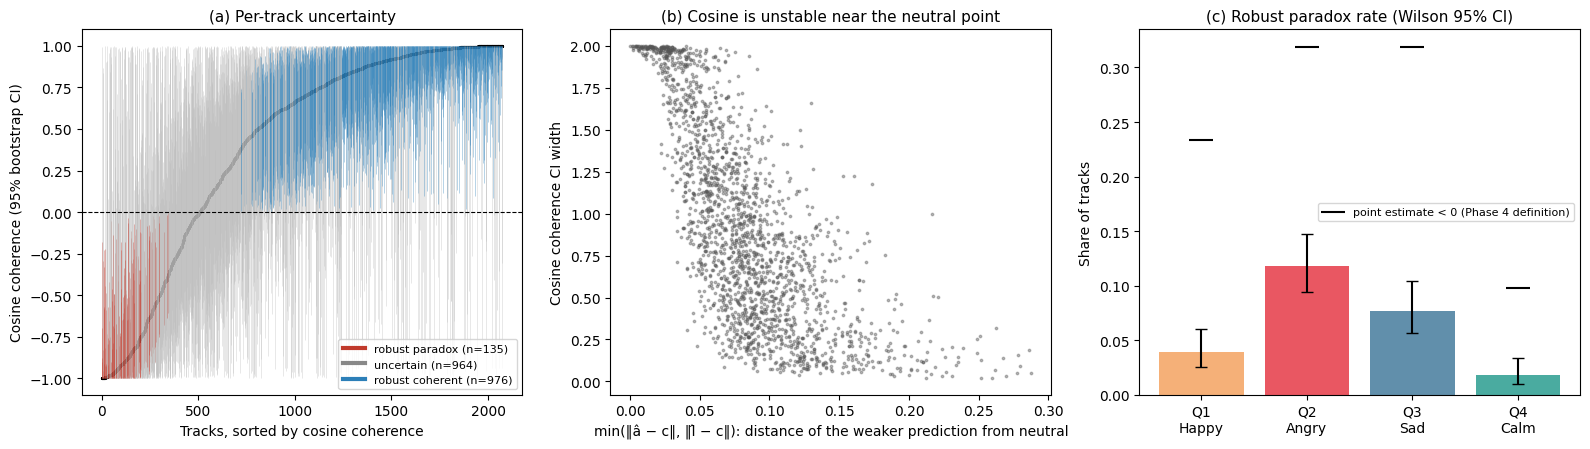

Saved: coherence_uncertainty.png


In [11]:
coh.drop(columns=['genres']).to_parquet(os.path.join(OUT_DIR, 'coherence_v2.parquet'), index=False)
print('Saved: coherence_v2.parquet, coherence_probe_metrics.csv, coherence_quadrant_summary.csv, '
      'coherence_quadrant_tests.csv, coherence_genre_tests.csv')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
# (a) point estimate with 95% CI, sorted
ax = axes[0]
s = coh.sort_values('coh_cos').reset_index(drop=True)
colors = s.status_cos.map({'robust paradox': '#c0392b', 'uncertain': '#bbbbbb', 'robust coherent': '#2c7fb8'})
ax.vlines(s.index, s.coh_cos_lo, s.coh_cos_hi, colors=colors, lw=0.4, alpha=0.6)
ax.scatter(s.index, s.coh_cos, s=1.5, c='black')
ax.axhline(0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Tracks, sorted by cosine coherence'); ax.set_ylabel('Cosine coherence (95% bootstrap CI)')
counts_st = coh.status_cos.value_counts()
ax.set_title('(a) Per-track uncertainty', fontsize=11)
for lbl, c in [('robust paradox', '#c0392b'), ('uncertain', '#888888'), ('robust coherent', '#2c7fb8')]:
    ax.plot([], [], color=c, lw=3, label=f'{lbl} (n={counts_st.get(lbl, 0)})')
ax.legend(fontsize=8, loc='lower right')
# (b) CI width vs distance from centre
ax = axes[1]
ax.scatter(coh.min_dev_from_center, coh.coh_cos_ci_width, s=3, alpha=0.4, color='#555555')
ax.set_xlabel('min(‖â − c‖, ‖l̂ − c‖): distance of the weaker prediction from neutral')
ax.set_ylabel('Cosine coherence CI width')
ax.set_title('(b) Cosine is unstable near the neutral point', fontsize=11)
# (c) robust paradox rate by quadrant
ax = axes[2]
x = np.arange(4)
ax.bar(x, qtab.robust_paradox_rate, color=[QCOL[q] for q in QUADS], alpha=0.85,
       yerr=[qtab.robust_paradox_rate - qtab.robust_ci_lo, qtab.robust_ci_hi - qtab.robust_paradox_rate], capsize=4)
ax.scatter(x, qtab.point_paradox_rate, marker='_', s=300, color='black', label='point estimate < 0 (Phase 4 definition)')
ax.set_xticks(x); ax.set_xticklabels([f'{q}\n{QLAB[q]}' for q in QUADS])
ax.set_ylabel('Share of tracks'); ax.set_title('(c) Robust paradox rate (Wilson 95% CI)', fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_uncertainty.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: coherence_uncertainty.png')